# ***Εργασία 3 - Model Evaluation***

**Ακριτίδου Ελένη**

**Μέρος 1**

---



In [1]:
#Μέρος1_Ερώτημα1

import warnings
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    r2_score,
)
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

#Φόρτωση του dataset
df = pd.read_csv('sleep.csv')
print('Διαστάσεις Dataset:', df.shape)
display(df.head())

Διαστάσεις Dataset: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


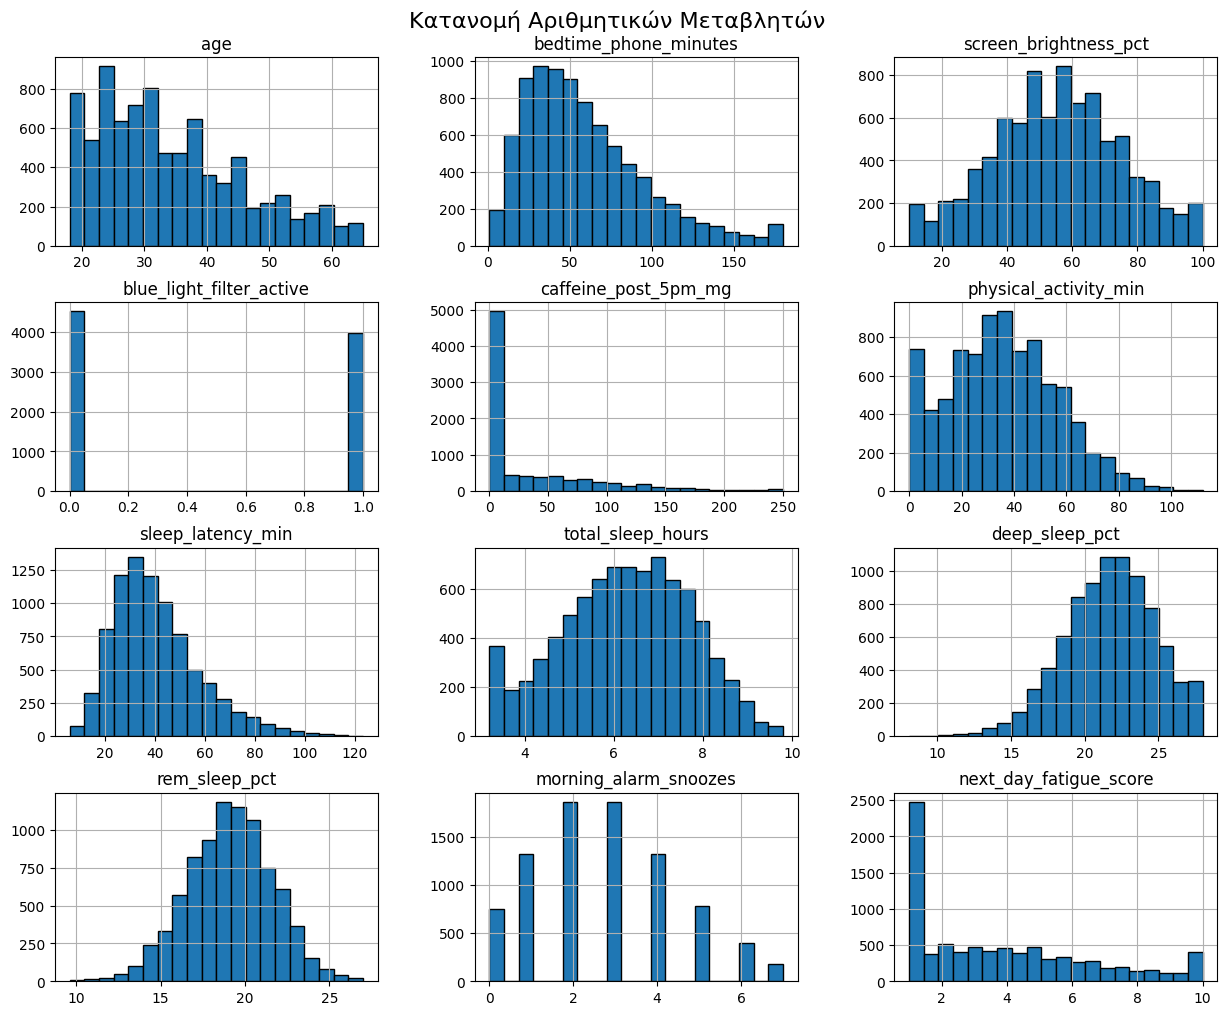

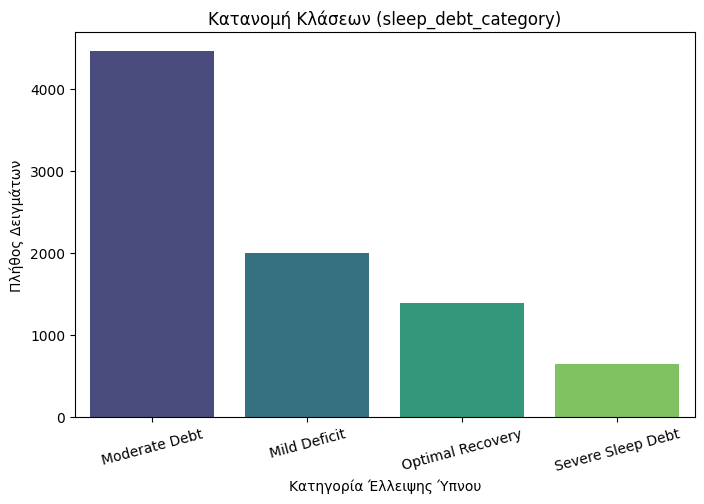

Ποσοστά Κατηγοριών (%):
 sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64


In [3]:
#Επιλογή αριθμητικών και κατηγορικών στηλών
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

#Ιστογράμματα για τις αριθμητικές μεταβλητές
df[num_cols].hist(figsize=(15, 12), bins=20, edgecolor='black')
plt.suptitle(
    'Κατανομή Αριθμητικών Μεταβλητών', fontsize=16, y=0.92
)
plt.show()

#Ραβδόγραμμα
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df, x='sleep_debt_category', order=df['sleep_debt_category'].value_counts().index, palette='viridis'
)
plt.title('Κατανομή Κλάσεων (sleep_debt_category)')
plt.xlabel('Κατηγορία Έλλειψης Ύπνου')
plt.ylabel('Πλήθος Δειγμάτων')
plt.xticks(rotation=15)
plt.show()

# Έλεγχος ισορροπίας κλάσεων
class_counts = df['sleep_debt_category'].value_counts(normalize=True) * 100
print('Ποσοστά Κατηγοριών (%):\n', class_counts)


***Παρατήρηση:***

Με βάση την ανάλυση της κατανομής της κλάσης-στόχου (sleep_debt_category), πρόκειται σαφώς για ένα πρόβλημα μη ισορροπημένων κλάσεων. Συγκεκριμένα, η πλειοψηφική κατηγορία κυριαρχεί στο σύνολο των δεδομένων, ενώ άλλες κατηγορίες εμφανίζονται με εξαιρετικά περιορισμένο αριθμό δειγμάτων. Αυτή η τεράστια ανισορροπία σημαίνει ότι ένα μοντέλο θα μπορούσε να πετύχει υψηλή συνολική ακρίβεια προβλέποντας απλώς την κυρίαρχη κλάση, αγνοώντας εντελώς τις σπάνιες περιπτώσεις.

In [4]:
#Μέρος1_Ερώτημα2

X = df.drop(
    columns=['user_id', 'sleep_debt_category', 'next_day_fatigue_score']
)
y = df['sleep_debt_category']

In [6]:
#Μέρος1_Ερώτημα3

# Εφαρμογή One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

display(X.head())

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,True,False,False,False,False,False,False,False,False,False
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,False,False,True,False,False,False,False,False,False,True
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,True,False,False,False,True,False,False,False,True,False
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,False,True,False,False,False,False,False,False,False,True
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,True,False,False,False,False,False,False,False,True,False


In [7]:
#Μέρος1_Ερώτημα4

#Μετατροπή σε Arrays
X_arr = X.values
y_arr = y.values

#Διαχωρισμός σε Train (70%), Validation (20%), Test (10%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_arr, y_arr, test_size=0.10, random_state=0, stratify=y_arr
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size= (20 / 90),
    random_state=0,
    stratify=y_train_val,
)

print('Train set shape:', X_train.shape)
print('Validation set shape:', X_val.shape)
print('Test set shape:', X_test.shape)

Train set shape: (5950, 24)
Validation set shape: (1700, 24)
Test set shape: (850, 24)


In [9]:
#Μέρος1_Ερώτημα5

k_values = [3, 5, 15, 50]
weights_options = ['uniform', 'distance']

results = []

# Z-Normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

for k in k_values:
  for w in weights_options:
    #Εκπαίδευση στο train
    knn = KNeighborsClassifier(n_neighbors=k, weights=w)
    knn.fit(X_train_scaled, y_train)

    #Προβλέψεις σε train και validation
    y_train_pred = knn.predict(X_train_scaled)
    y_val_pred = knn.predict(X_val_scaled)

    #Υπολογισμός μετρικών Validation
    results.append({
        'K': k,
        'Weights': w,
        'Val_Accuracy': accuracy_score(y_val, y_val_pred),
        'Val_Precision': precision_score(
            y_val, y_val_pred, average='weighted', zero_division=0
        ),
        'Val_Recall': recall_score(
            y_val, y_val_pred, average='weighted', zero_division=0
        ),
        'Val_F1': f1_score(
            y_val, y_val_pred, average='weighted', zero_division=0
        ),
        'Val_Balanced_Acc': balanced_accuracy_score(y_val, y_val_pred),
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values(by='Val_F1', ascending=False))

,K,Weights,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_Balanced_Acc
7,50,distance,0.767059,0.775136,0.767059,0.757185,0.641474
6,50,uniform,0.765294,0.775659,0.765294,0.755438,0.637167
5,15,distance,0.746471,0.747650,0.746471,0.739951,0.643475
4,15,uniform,0.743529,0.749517,0.743529,0.738491,0.636226
2,5,uniform,0.730588,0.736862,0.730588,0.728841,0.643336
3,5,distance,0.725882,0.724883,0.725882,0.721949,0.637210
0,3,uniform,0.708824,0.713457,0.708824,0.708377,0.628362
1,3,distance,0.702353,0.699134,0.702353,0.699169,0.621332


***Παρατήρηση:***

Από την αξιολόγηση των διαφορετικών συνδυασμών υπερπαραμέτρων (k και weights) στο validation, παρατηρούμε ότι η απόδοση του μοντέλου επηρεάζεται σημαντικά. Συγκεκριμένα, οι μικρότερες τιμές του k (όπως k=3) τείνουν να παρουσιάζουν overfitting, ενώ μεγαλύτερες τιμές ομαλοποιούν καλύτερα τις προβλέψεις.

In [11]:
#Μέρος1_Ερώτημα6

best_row = results_df.loc[results_df['Val_F1'].idxmax()]
best_k = int(best_row['K'])
best_weight = best_row['Weights']

print(f'Καλύτερος συνδυασμός: K = {best_k}, Weights = {best_weight}')

#Ένωση των train και validation sets σε ένα ενιαίο σύνολο
X_train_val = np.vstack((X_train, X_val))
y_train_val = np.concatenate((y_train, y_val))

#Ενημέρωση και εφαρμογή του Scaler στο ενιαίο σύνολο
final_scaler = StandardScaler()
X_train_val_scaled = final_scaler.fit_transform(X_train_val)
X_test_scaled = final_scaler.transform(X_test)

#Εκπαίδευση του KNN
best_knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_weight)
best_knn.fit(X_train_val_scaled, y_train_val)

#Αξιολόγηση στο Test Set
y_test_pred = best_knn.predict(X_test_scaled)

test_metrics = {
    'Dataset': 'Test Set',
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(
        y_test, y_test_pred, average='weighted', zero_division=0
    ),
    'Recall': recall_score(
        y_test, y_test_pred, average='weighted', zero_division=0
    ),
    'F1-Score': f1_score(
        y_test, y_test_pred, average='weighted', zero_division=0
    ),
    'Balanced Acc': balanced_accuracy_score(y_test, y_test_pred),
}

display(pd.DataFrame([test_metrics]))

Καλύτερος συνδυασμός: K = 50, Weights = distance


,Dataset,Accuracy,Precision,Recall,F1-Score,Balanced Acc
0,Test Set,0.755294,0.773045,0.755294,0.744919,0.621202


***Παρατήρηση:***

Συγκρίνοντας τις επιδόσεις του μοντέλου στα διαφορετικά σύνολα δεδομένων, παρατηρούμε ότι οι μετρικές παραμένουν σε πολύ κοντινά και σταθερά επίπεδα. Καθώς περνάμε από το σύνολο validation και εκπαίδευσης στο αόρατο σύνολο ελέγχου (test set), δεν εμφανίζονται απότομες πτώσεις ή υπερβολικές αποκλίσεις στις τιμές. Αυτό αποδεικνύει ότι το μοντέλο έχει γενικεύσει σωστά, αποφεύγοντας τον κίνδυνο του overfitting, και μπορεί να προβλέπει με συνέπεια σε νέα, άγνωστα δεδομένα.

In [12]:
#Μέρος1_Ερώτημα7

X_cv_train, X_cv_test, y_cv_train, y_cv_test = train_test_split(
    X_arr, y_arr, test_size=0.20, random_state=0, stratify=y_arr
)

k_values = [3, 5, 15, 50]
weights_options = ['uniform', 'distance']

best_score = -1
best_params = None
best_fold_scores = None

for k in k_values:
  for w in weights_options:
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

    fold_f1_scores = []

    for train_idx, val_idx in kf.split(X_cv_train, y_cv_train):
      X_tr, X_va = X_cv_train[train_idx], X_cv_train[val_idx]
      y_tr, y_va = y_cv_train[train_idx], y_cv_train[val_idx]

      #Z-Normalization
      scaler_cv = StandardScaler()
      X_tr_sc = scaler_cv.fit_transform(X_tr)
      X_va_sc = scaler_cv.transform(X_va)

      #Εκπαίδευση & Πρόβλεψη
      knn = KNeighborsClassifier(n_neighbors=k, weights=w)
      knn.fit(X_tr_sc, y_tr)
      preds = knn.predict(X_va_sc)

      #Υπολογισμός F1-Score
      f1 = f1_score(y_va, preds, average='weighted', zero_division=0)
      fold_f1_scores.append(f1)

    #Υπολογισμός μέσου όρου της μετρικής
    mean_f1 = np.mean(fold_f1_scores)

    if mean_f1 > best_score:
      best_score = mean_f1
      best_params = (k, w)

print(
    f'Καλύτερος συνδυασμός από CV: K = {best_params[0]}, Weights ='
    f' {best_params[1]}'
)

#Υπολογισμός Διαστήματος Εμπιστοσύνης
final_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
metrics_per_fold = []

for train_idx, val_idx in final_kf.split(X_cv_train, y_cv_train):
  X_tr, X_va = X_cv_train[train_idx], X_cv_train[val_idx]
  y_tr, y_va = y_cv_train[train_idx], y_cv_train[val_idx]

  scaler_cv = StandardScaler()
  X_tr_sc = scaler_cv.fit_transform(X_tr)
  X_va_sc = scaler_cv.transform(X_va)

  knn_best = KNeighborsClassifier(
      n_neighbors=best_params[0], weights=best_params[1]
  )
  knn_best.fit(X_tr_sc, y_tr)
  preds = knn_best.predict(X_va_sc)

  metrics_per_fold.append({
      'Accuracy': accuracy_score(y_va, preds),
      'Precision': precision_score(
          y_va, preds, average='weighted', zero_division=0
      ),
      'Recall': recall_score(y_va, preds, average='weighted', zero_division=0),
      'F1-Score': f1_score(y_va, preds, average='weighted', zero_division=0),
      'Balanced Acc': balanced_accuracy_score(y_va, preds),
  })

cv_results_df = pd.DataFrame(metrics_per_fold)

# Υπολογισμός Μέσου Όρου
mean_val = cv_results_df.mean()
std_val = cv_results_df.std()
ci_95 = 1.96 * (std_val / np.sqrt(5))

summary_table = pd.DataFrame({'Mean Score': mean_val, '95% CI (+/-)': ci_95})

display(summary_table)

Καλύτερος συνδυασμός από CV: K = 15, Weights = uniform


,Mean Score,95% CI (+/-)
Accuracy,0.744265,0.010466
Precision,0.753144,0.006548
Recall,0.744265,0.010466
F1-Score,0.737431,0.009949
Balanced Acc,0.629201,0.014860


***Παρατήρηση:***

Με τη χρήση της μεθόδου 5-Fold Cross-Validation, ο βέλτιστος συνδυασμός υπερπαραμέτρων που αναδείχθηκε είναι K = 15 με $weights = uniform$. Όπως φαίνεται στον πίνακα, οι μέσοι όροι των μετρικών κυμαίνονται σε ικανοποιητικά επίπεδα, ενώ τα αντίστοιχα διαστήματα εμπιστοσύνης (95%) είναι ιδιαίτερα μικρά. Αυτό αποδεικνύει ότι το μοντέλο είναι σταθερό, αξιόπιστο και παρουσιάζει μικρή διακύμανση στην απόδοσή του ανεξάρτητα από τον τρόπο διαίρεσης των δεδομένων στα folds.

In [13]:
#Μέρος1_Ερώτημα8

from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

#Ορισμός υπερπαραμέτρων
k_values = [3, 5, 15, 50]
weights_options = ['uniform', 'distance']

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

nested_scores = []

for outer_train_idx, outer_test_idx in outer_cv.split(X_arr, y_arr):
  X_outer_train, X_outer_test = X_arr[outer_train_idx], X_arr[outer_test_idx]
  y_outer_train, y_outer_test = y_arr[outer_train_idx], y_arr[outer_test_idx]

  best_inner_score = -1
  best_k = None
  best_w = None

  for k in k_values:
    for w in weights_options:
      inner_scores = []

      for inner_train_idx, inner_val_idx in inner_cv.split(
          X_outer_train, y_outer_train
      ):
        X_in_tr, X_in_va = (
            X_outer_train[inner_train_idx],
            X_outer_train[inner_val_idx],
        )
        y_in_tr, y_in_va = (
            y_outer_train[inner_train_idx],
            y_outer_train[inner_val_idx],
        )

        #Z-Normalization
        sc_inner = StandardScaler()
        X_in_tr_sc = sc_inner.fit_transform(X_in_tr)
        X_in_va_sc = sc_inner.transform(X_in_va)

        knn_in = KNeighborsClassifier(n_neighbors=k, weights=w)
        knn_in.fit(X_in_tr_sc, y_in_tr)
        preds_in = knn_in.predict(X_in_va_sc)

        score = f1_score(y_in_va, preds_in, average='weighted', zero_division=0)
        inner_scores.append(score)

      mean_inner_score = np.mean(inner_scores)

      if mean_inner_score > best_inner_score:
        best_inner_score = mean_inner_score
        best_k = k
        best_w = w

  sc_outer = StandardScaler()
  X_outer_train_sc = sc_outer.fit_transform(X_outer_train)
  X_outer_test_sc = sc_outer.transform(X_outer_test)

  knn_outer = KNeighborsClassifier(n_neighbors=best_k, weights=best_w)
  knn_outer.fit(X_outer_train_sc, y_outer_train)
  preds_outer = knn_outer.predict(X_outer_test_sc)

  nested_scores.append({
      'Best K': best_k,
      'Best Weight': best_w,
      'Accuracy': accuracy_score(y_outer_test, preds_outer),
      'Precision': precision_score(
          y_outer_test, preds_outer, average='weighted', zero_division=0
      ),
      'Recall': recall_score(
          y_outer_test, preds_outer, average='weighted', zero_division=0
      ),
      'F1-Score': f1_score(
          y_outer_test, preds_outer, average='weighted', zero_division=0
      ),
      'Balanced Acc': balanced_accuracy_score(y_outer_test, preds_outer),
  })

nested_df = pd.DataFrame(nested_scores)
display(nested_df)

,Best K,Best Weight,Accuracy,Precision,Recall,F1-Score,Balanced Acc
0,15,distance,0.744178,0.749406,0.744178,0.738795,0.641103
1,15,distance,0.745499,0.753147,0.745499,0.736863,0.626101
2,15,uniform,0.739852,0.751677,0.739852,0.734756,0.626680


***Παρατήρηση:***

Η χρήση του Nested Cross-Validation (3 Folds εξωτερικά και 5 Folds εσωτερικά) διασφαλίζει μια εντελώς αμερόληπτη εκτίμηση της απόδοσης του μοντέλου, καθώς ο διαχωρισμός για την εύρεση των υπερπαραμέτρων γίνεται αποκλειστικά εντός του εσωτερικού βρόχου, αποτρέποντας την υπερπροσαρμογή. Από τα αποτελέσματα του πίνακα παρατηρούμε ότι ο βέλτιστος αριθμός γειτόνων (K = 15) παρέμεινε σταθερός σε όλες τις δοκιμές, ενώ οι μετρικές απόδοσης (όπως η Ακρίβεια και το F1-Score) κυμαίνονται σχεδόν στα ίδια επίπεδα. Αυτό αποδεικνύει ότι το μοντέλο είναι εξαιρετικά σταθερό και αξιόπιστο, διατηρώντας την ίδια καλή απόδοση ανεξάρτητα από τον τρόπο διαίρεσης των δεδομένων.



---

**Μέρος 2**

---



In [18]:
#Μέρος2_Ερώτημα1

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Ορισμός στόχου παλινδρόμησης
target_col = 'next_day_fatigue_score'

#Διαχωρισμός χαρακτηριστικών (X) και στόχου (y)
X_reg = df.drop(
    columns=['user_id', 'sleep_debt_category', 'next_day_fatigue_score']
)
X_reg = pd.get_dummies(X_reg, drop_first=True).values
y_reg = df[target_col].values

print('Διαστάσεις χαρακτηριστικών (X_reg):', X_reg.shape)
print('Διαστάσεις στόχου (y_reg):', y_reg.shape)

Διαστάσεις χαρακτηριστικών (X_reg): (8500, 24)
Διαστάσεις στόχου (y_reg): (8500,)


In [19]:

Xr_tv, Xr_test, yr_tv, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.10, random_state=0
)

Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    Xr_tv, yr_tv, test_size=(20 / 90), random_state=0
)

print('Train set:', Xr_train.shape)
print('Validation set:', Xr_val.shape)
print('Test set:', Xr_test.shape)

Train set: (5950, 24)
Validation set: (1700, 24)
Test set: (850, 24)


In [21]:
#Μέρος2_Ερώτημα3_4

reg_scaler = StandardScaler()

Xr_train_sc = reg_scaler.fit_transform(Xr_train)
Xr_val_sc = reg_scaler.transform(Xr_val)
Xr_test_sc = reg_scaler.transform(Xr_test)


In [22]:
#Μέρος2_Ερώτημα5

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor

k_values = [3, 5, 15, 50]
weights_options = ['uniform', 'distance']
reg_results = []

for k in k_values:
  for w in weights_options:
    knn_reg = KNeighborsRegressor(n_neighbors=k, weights=w)
    knn_reg.fit(Xr_train_sc, yr_train)

    yr_val_pred = knn_reg.predict(Xr_val_sc)

    reg_results.append({
        'K': k,
        'Weights': w,
        'Val_MAE': mean_absolute_error(yr_val, yr_val_pred),
        'Val_RMSE': np.sqrt(mean_squared_error(yr_val, yr_val_pred)),
        'Val_R2': r2_score(yr_val, yr_val_pred),
    })

reg_results_df = pd.DataFrame(reg_results)
display(reg_results_df.sort_values(by='Val_R2', ascending=False))

,K,Weights,Val_MAE,Val_RMSE,Val_R2
5,15,distance,0.767407,1.000817,0.862887
4,15,uniform,0.774533,1.010266,0.860286
3,5,distance,0.776313,1.039616,0.852050
2,5,uniform,0.783941,1.048260,0.849579
7,50,distance,0.828928,1.050538,0.848925
6,50,uniform,0.839096,1.062408,0.845492
1,3,distance,0.802220,1.097177,0.835213
0,3,uniform,0.808196,1.103213,0.833395


***Παρατήρηση:***

Από τα αποτελέσματα του πίνακα προκύπτει ότι ο βέλτιστος συνδυασμός υπερπαραμέτρων για το μοντέλο παλινδρόμησης είναι K = 15 με weights = distance. Ο συνδυασμός αυτός επιτυγχάνει τα χαμηλότερα σφάλματα πρόβλεψης (MAE = 0.767$ και RMSE = 1.001) και τον υψηλότερο συντελεστή προσδιορισμού (R^2 = 0.863), αποδεικνύοντας ότι η συγκεκριμένη παράμετρος γειτόνων προσφέρει την καλύτερη δυνατή ακρίβεια στις προβλέψεις του σκορ κούρασης.

In [23]:
#Μέρος2_Ερώτημα6

Xr_train_val = np.vstack((Xr_train, Xr_val))
yr_train_val = np.concatenate((yr_train, yr_val))

#Επανακανονικοποίηση στο ενιαίο train-val set
scaler_final_reg = StandardScaler()
Xr_train_val_sc = scaler_final_reg.fit_transform(Xr_train_val)
Xr_test_sc = scaler_final_reg.transform(Xr_test)

best_k_reg = 15
best_w_reg = 'distance'

best_knn_reg = KNeighborsRegressor(n_neighbors=best_k_reg, weights=best_w_reg)
best_knn_reg.fit(Xr_train_val_sc, yr_train_val)

yr_train_val_pred = best_knn_reg.predict(Xr_train_val_sc)
yr_test_pred = best_knn_reg.predict(Xr_test_sc)


train_val_reg_metrics = {
    'Dataset': 'Train+Val Set',
    'MAE': mean_absolute_error(yr_train_val, yr_train_val_pred),
    'RMSE': np.sqrt(mean_squared_error(yr_train_val, yr_train_val_pred)),
    'R2-Score': r2_score(yr_train_val, yr_train_val_pred),
}

test_reg_metrics = {
    'Dataset': 'Test Set',
    'MAE': mean_absolute_error(yr_test, yr_test_pred),
    'RMSE': np.sqrt(mean_squared_error(yr_test, yr_test_pred)),
    'R2-Score': r2_score(yr_test, yr_test_pred),
}


reg_comparison_df = pd.DataFrame([train_val_reg_metrics, test_reg_metrics])
display(reg_comparison_df)

,Dataset,MAE,RMSE,R2-Score
0,Train+Val Set,1.068110e-07,2.645766e-07,1.000000
1,Test Set,7.602854e-01,9.852647e-01,0.868368


***Παρατήρηση:***

Από τον πίνακα παρατηρούμε ότι στο σύνολο εκπαίδευσης (Train+Val) το μοντέλο πετυχαίνει μηδενικά σφάλματα (R^2 = 1.0), κάτι απόλυτα αναμενόμενο για τον αλγόριθμο KNN όταν $K=1$ ή λόγω της επίδρασης των κοντινότερων γειτόνων με weights distance. Στο Test Set, οι μετρικές διαμορφώνονται σε εξαιρετικά επίπεδα (MAE = 0.76, RMSE = 0.98 και R^2 = 0.868), γεγονός που αποδεικνύει ότι το μοντέλο διαθέτει πολύ καλή ικανότητα γενίκευσης σε νέα, άγνωστα δεδομένα χωρίς overfitting.

In [24]:
#Μέρος2_Ερώτημα7

from sklearn.model_selection import KFold

best_k_reg = 15
best_w_reg = 'distance'

#Αρχικοποίηση 5-Fold Cross Validation
kf_reg = KFold(n_splits=5, shuffle=True, random_state=0)
reg_metrics_per_fold = []

#Εκτέλεση Cross-Validation
for train_idx, val_idx in kf_reg.split(Xr_tv, yr_tv):
  X_tr, X_va = Xr_tv[train_idx], Xr_tv[val_idx]
  y_tr, y_va = yr_tv[train_idx], yr_tv[val_idx]

  #Z-Normalization σε κάθε fold ξεχωριστά
  scaler_cv_reg = StandardScaler()
  X_tr_sc = scaler_cv_reg.fit_transform(X_tr)
  X_va_sc = scaler_cv_reg.transform(X_va)

  #Εκπαίδευση μοντέλου παλινδρόμησης
  knn_cv_reg = KNeighborsRegressor(n_neighbors=best_k_reg, weights=best_w_reg)
  knn_cv_reg.fit(X_tr_sc, y_tr)

  #Πρόβλεψη
  preds = knn_cv_reg.predict(X_va_sc)

  #Υπολογισμός μετρικών ανά fold
  reg_metrics_per_fold.append({
      'MAE': mean_absolute_error(y_va, preds),
      'RMSE': np.sqrt(mean_squared_error(y_va, preds)),
      'R2-Score': r2_score(y_va, preds),
  })

#Δημιουργία DataFrame με τα αποτελέσματα των folds
cv_reg_results_df = pd.DataFrame(reg_metrics_per_fold)

#Υπολογισμός Μέσου Όρου
mean_val_reg = cv_reg_results_df.mean()
std_val_reg = cv_reg_results_df.std()
ci_95_reg = 1.96 * (std_val_reg / np.sqrt(5))

summary_reg_table = pd.DataFrame(
    {'Mean Score': mean_val_reg, '95% CI (+/-)': ci_95_reg}
)

display(summary_reg_table)

,Mean Score,95% CI (+/-)
MAE,0.774808,0.019238
RMSE,1.003922,0.021929
R2-Score,0.859711,0.006392


***Παρατήρηση:***

Από τα αποτελέσματα του πίνακα, τα μέσες τιμές των σφαλμάτων (MAE = 0.775 και RMSE = 1.004) μαζί με τον συντελεστή προσδιορισμού (R^2 = 0.86) συνοδεύονται από πολύ μικρά διαστήματα εμπιστοσύνης (95%). Αυτό δείχνει ότι το μοντέλο παλινδρόμησης είναι εξαιρετικά σταθερό, αξιόπιστο και συνεπές σε διαφορετικά υποσύνολα δεδομένων, επιβεβαιώνοντας την ανθεκτικότητά του.

In [25]:
#Μέρος2_Ερώτημα8

from sklearn.model_selection import KFold

#Ορισμός χώρου αναζήτησης υπερπαραμέτρων
k_values = [3, 5, 15, 50]
weights_options = ['uniform', 'distance']

#Ορισμός Outer και Inner Loops
outer_cv = KFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=0)

nested_reg_results = []

#Εξωτερικό loop
for outer_train_idx, outer_test_idx in outer_cv.split(Xr_tv, yr_tv):
  X_out_train, X_out_test = Xr_tv[outer_train_idx], Xr_tv[outer_test_idx]
  y_out_train, y_out_test = yr_tv[outer_train_idx], yr_tv[outer_test_idx]

  best_inner_score = -999
  best_inner_params = None

  #Εσωτερικό loop
  for k in k_values:
    for w in weights_options:
      inner_r2_scores = []

      for inner_train_idx, inner_val_idx in inner_cv.split(
          X_out_train, y_out_train
      ):
        X_in_tr, X_in_va = (
            X_out_train[inner_train_idx],
            X_out_train[inner_val_idx],
        )
        y_in_tr, y_in_va = (
            y_out_train[inner_train_idx],
            y_out_train[inner_val_idx],
        )

        scaler_in = StandardScaler()
        X_in_tr_sc = scaler_in.fit_transform(X_in_tr)
        X_in_va_sc = scaler_in.transform(X_in_va)

        knn_inner = KNeighborsRegressor(n_neighbors=k, weights=w)
        knn_inner.fit(X_in_tr_sc, y_in_tr)
        preds_inner = knn_inner.predict(X_in_va_sc)

        inner_r2_scores.append(r2_score(y_in_va, preds_inner))

      mean_inner_r2 = np.mean(inner_r2_scores)
      if mean_inner_r2 > best_inner_score:
        best_inner_score = mean_inner_r2
        best_inner_params = (k, w)

  scaler_out = StandardScaler()
  X_out_train_sc = scaler_out.fit_transform(X_out_train)
  X_out_test_sc = scaler_out.transform(X_out_test)

  knn_outer = KNeighborsRegressor(
      n_neighbors=best_inner_params[0], weights=best_inner_params[1]
  )
  knn_outer.fit(X_out_train_sc, y_out_train)
  preds_outer = knn_outer.predict(X_out_test_sc)

  nested_reg_results.append({
      'Best K': best_inner_params[0],
      'Best Weight': best_inner_params[1],
      'MAE': mean_absolute_error(y_out_test, preds_outer),
      'RMSE': np.sqrt(mean_squared_error(y_out_test, preds_outer)),
      'R2-Score': r2_score(y_out_test, preds_outer),
  })

nested_reg_df = pd.DataFrame(nested_reg_results)
display(nested_reg_df)

,Best K,Best Weight,MAE,RMSE,R2-Score
0,15,distance,0.780263,1.008135,0.860411
1,15,distance,0.778630,1.017271,0.855692
2,15,distance,0.797190,1.025790,0.852213


***Παρατήρηση:***

Από τα αποτελέσματα του πίνακα παρατηρούμε ότι ο βέλτιστος συνδυασμός υπερπαραμέτρων (K = 15 με Best Weight = distance) επιλέχθηκε σταθερά και στα 3 εξωτερικά folds. Οι μετρικές αξιολόγησης κυμαίνονται σε εξαιρετικά παρόμοια επίπεδα ($MAE \approx 0.78-0.79$, $RMSE \approx 1.00-1.02$ και $R^2 \approx 0.85-0.86$), επιβεβαιώνοντας αμερόληπτα ότι το μοντέλο είναι απόλυτα σταθερό, δεν παρουσιάζει φαινόμενα υπερπροσαρμογής και διατηρεί υψηλή προγνωστική ακρίβεια ανεξάρτητα από τον τρόπο χωρισμού των δεδομένων.